# 02 - Preprocessing (32-city dataset)
Converts the raw Sentinel-1 and WorldCover exports for all 32 cities into matched, normalized patch-pairs ready for model training. Builds on `01_data_collection.ipynb` and `01b_data_collection_additional_cities.ipynb`, which together produced `dataset_metadata.csv` covering 32 cities x 12 months.

## Cell 1: Mount Drive and install packages
Mounts Google Drive as the data source and sets up the output folder for processed patches. rasterio and scikit-image are the libraries used for reading geospatial raster files and image-level array operations.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install rasterio scikit-image -q

import os
DRIVE_FOLDER = '/content/drive/MyDrive/lulc_dataset'
PATCH_FOLDER = '/content/drive/MyDrive/lulc_dataset/patches'
os.makedirs(PATCH_FOLDER, exist_ok=True)
print("Working folder:", DRIVE_FOLDER)
print("Patch output folder:", PATCH_FOLDER)

Mounted at /content/drive
Working folder: /content/drive/MyDrive/lulc_dataset
Patch output folder: /content/drive/MyDrive/lulc_dataset/patches


## Cell 2: Load metadata and confirm dB scale
Loads the dataset index covering all 32 cities and checks the pixel value range of a sample file. The Sentinel-1 GRD collection in Earth Engine is already radiometrically calibrated and delivered in dB, so a separate calibration step is not required. VV/VH values in the -25 to 5 dB range confirm this.

In [2]:
import pandas as pd
import rasterio
import numpy as np

metadata_df = pd.read_csv(f"{DRIVE_FOLDER}/dataset_metadata.csv")
print(f"Loaded metadata for {len(metadata_df)} city-month pairs")
print(f"Total cities: {metadata_df['city'].nunique()}")
print(metadata_df.groupby('city').size())

sample = metadata_df.iloc[0]
with rasterio.open(f"{DRIVE_FOLDER}/{sample['s1_file']}") as src:
    vv = src.read(1)
    vh = src.read(2)

print(f"\nVV range: {vv.min():.2f} to {vv.max():.2f} dB")
print(f"VH range: {vh.min():.2f} to {vh.max():.2f} dB")

Loaded metadata for 384 city-month pairs
Total cities: 32
city
Amsterdam       12
Bangkok         12
Berlin          12
Bremen          12
Brussels        12
Cairo           12
CapeTown        12
Christchurch    12
Copenhagen      12
Dresden         12
EastLondon      12
Freiburg        12
Hamburg         12
Hamilton        12
Kiel            12
Lagos           12
Leipzig         12
London          12
Melbourne       12
Mumbai          12
Munich          12
Munster         12
Portland        12
Prague          12
Rostock         12
Seoul           12
Stuttgart       12
Toronto         12
Vancouver       12
Vienna          12
Warsaw          12
Zurich          12
dtype: int64

VV range: -25.58 to 18.46 dB
VH range: -39.83 to 9.47 dB


## Cell 3: Diagnostic check on raw export dimensions
Before processing, checks the raw pixel dimensions of the Sentinel-1 and WorldCover exports for every city. This catches any city whose export came back a different size than the others, which would otherwise only show up later as an unexplained drop in patch count. EastLondon and Hamilton are compared directly since they used the same bounding box size and should match closely; a city with meaningfully smaller dimensions than the rest points to an export problem, not a preprocessing bug.

In [3]:
import rasterio
import time

def with_retries(func, *args, retries=3, delay=15, **kwargs):
    """Runs func(*args, **kwargs), retrying on a Drive read failure.
    Remounts Drive before the final attempt, since a stale mount sometimes
    needs a fresh remount rather than just waiting."""
    last_error = None
    for attempt in range(1, retries + 1):
        try:
            return func(*args, **kwargs)
        except (OSError, rasterio.errors.RasterioIOError) as e:
            last_error = e
            if attempt == retries:
                break
            if attempt == retries - 1:
                try:
                    drive.mount('/content/drive', force_remount=True)
                except Exception:
                    pass
            time.sleep(delay)
    raise last_error


def get_shape(path):
    with rasterio.open(path) as src:
        return (src.height, src.width)


print("Raw raster dimensions per city (min/max height and width across all 12 months):\n")
shape_summary = []
unreadable_files = []

for city in sorted(metadata_df['city'].unique()):
    rows = metadata_df[metadata_df['city'] == city]
    heights, widths = [], []
    for _, row in rows.iterrows():
        s1_path = f"{DRIVE_FOLDER}/{row['s1_file']}"
        try:
            h, w = with_retries(get_shape, s1_path)
            heights.append(h)
            widths.append(w)
        except Exception as e:
            unreadable_files.append((row['s1_file'], str(e)))
            print(f"  [UNREADABLE after retries] {row['s1_file']}: {e}")

    if heights:
        shape_summary.append({
            "city": city,
            "min_height": min(heights), "max_height": max(heights),
            "min_width": min(widths), "max_width": max(widths),
            "months_readable": len(heights),
        })
    else:
        shape_summary.append({
            "city": city,
            "min_height": None, "max_height": None,
            "min_width": None, "max_width": None,
            "months_readable": 0,
        })

shape_df = pd.DataFrame(shape_summary)
print(shape_df.to_string(index=False))

if unreadable_files:
    print(f"\n{len(unreadable_files)} file(s) could not be read even after retries:")
    for fname, err in unreadable_files:
        print(f"  {fname}: {err}")
else:
    print("\nAll files read successfully, no unreadable files.")

print("\n--- EastLondon vs Hamilton, month by month ---")
for city in ['EastLondon', 'Hamilton']:
    rows = metadata_df[metadata_df['city'] == city]
    print(f"\n{city}:")
    for _, row in rows.iterrows():
        s1_path = f"{DRIVE_FOLDER}/{row['s1_file']}"
        wc_path = f"{DRIVE_FOLDER}/{row['wc_file']}"
        try:
            s1_shape = with_retries(get_shape, s1_path)
            wc_shape = with_retries(get_shape, wc_path)
            print(f"  {row['year']}-{row['month']:02d}: s1={s1_shape} wc={wc_shape}")
        except Exception as e:
            print(f"  {row['year']}-{row['month']:02d}: FAILED to read - {e}")


Raw raster dimensions per city (min/max height and width across all 12 months):

        city  min_height  max_height  min_width  max_width  months_readable
   Amsterdam        1225        1225       2228       2228               12
     Bangkok        1225        1225       2228       2228               12
      Berlin        1226        1226       2227       2227               12
      Bremen        1226        1226       2228       2228               12
    Brussels        1226        1226       2228       2228               12
       Cairo        1225        1225       2227       2227               12
    CapeTown        1225        1225       2228       2228               12
Christchurch        1226        1226       2227       2227               12
  Copenhagen        1225        1225       2227       2227               12
     Dresden        1225        1225       2227       2227               12
  EastLondon        1225        1225       2228       2228               12
    Fre

## Cell 4: Speckle filtering
Speckle is granular noise inherent to SAR imagery, caused by coherent interference of radar backscatter within each resolution cell. A median filter suppresses this noise while preserving land-cover boundaries, and is a standard, low-cost despeckling method.

In [4]:
from scipy.ndimage import median_filter

def despeckle(band, size=3):
    return median_filter(band, size=size)

## Cell 5: Normalization
Rescales dB values to the 0 to 1 range expected by deep learning architectures. A fixed clipping range of -25 to 5 dB is used so normalization is consistent across all 32 cities and months. Terrain correction is already applied by Earth Engine's Sentinel-1 GRD processing, so no additional geometric correction step is needed here.

In [5]:
def normalize(band, min_db=-25, max_db=5):
    clipped = np.clip(band, min_db, max_db)
    return (clipped - min_db) / (max_db - min_db)

## Cell 6: Patching function
Cuts each image and its matching label into fixed-size 256x256 patches. Patching limits memory and compute load during training and produces many training examples per city. Only complete patches are kept, so partial edge regions are discarded.

In [6]:
PATCH_SIZE = 256

def extract_patches(image_array, label_array, patch_size=PATCH_SIZE):
    patches = []
    h, w = label_array.shape
    for y in range(0, h - patch_size + 1, patch_size):
        for x in range(0, w - patch_size + 1, patch_size):
            img_patch = image_array[:, y:y+patch_size, x:x+patch_size]
            lbl_patch = label_array[y:y+patch_size, x:x+patch_size]
            if img_patch.shape[1] == patch_size and img_patch.shape[2] == patch_size:
                patches.append((img_patch, lbl_patch))
    return patches

## Cell 7: Process all city-month pairs into patches
For every city-month pair across all 32 cities, crops the Sentinel-1 and WorldCover arrays to their common minimum shape to correct the 1-pixel edge mismatch produced during export clipping, applies speckle filtering and normalization to each SAR band, stacks VV and VH into a 2-channel array, and extracts aligned image-label patches. Each patch pair is saved to disk. This cell is resumable: it checkpoints progress to `patch_metadata.csv` every 5 city-month pairs, and on a fresh run it first checks that file for city-month pairs already processed and skips them. It also retries automatically on a Drive disconnect: every disk read or write goes through a retry wrapper that waits and tries again up to 3 times, remounting Drive before the final attempt, instead of silently failing or crashing the whole cell on a transient disconnect.

In [7]:
import time

def with_retries(func, *args, retries=3, delay=15, **kwargs):
    """Runs func(*args, **kwargs), retrying on a Drive disconnect (OSError 107).
    Remounts Drive before the final attempt, since a stale mount sometimes
    needs a fresh remount rather than just waiting."""
    last_error = None
    for attempt in range(1, retries + 1):
        try:
            return func(*args, **kwargs)
        except OSError as e:
            last_error = e
            print(f"    [retry {attempt}/{retries}] disk error: {e}")
            if attempt == retries:
                break
            if attempt == retries - 1:
                try:
                    print("    [retry] remounting Drive...")
                    drive.mount('/content/drive', force_remount=True)
                except Exception as mount_err:
                    print(f"    [retry] remount failed: {mount_err}")
            time.sleep(delay)
    raise last_error


def read_s1(path):
    with rasterio.open(path) as src:
        return src.read(1), src.read(2)

def read_label(path):
    with rasterio.open(path) as src:
        return src.read(1)

def save_patch(path, array):
    np.save(path, array)

def save_csv(df, path):
    df.to_csv(path, index=False)


patch_csv_path = f"{DRIVE_FOLDER}/patch_metadata.csv"

if os.path.exists(patch_csv_path):
    existing_patch_df = pd.read_csv(patch_csv_path)
    already_done = set(zip(existing_patch_df['city'], existing_patch_df['year'], existing_patch_df['month']))
    patch_records = existing_patch_df.to_dict('records')
    print(f"Found existing patch_metadata.csv with {len(patch_records)} patches from a previous run.")
    print(f"{len(already_done)} city-month pairs already processed, these will be skipped.")
else:
    already_done = set()
    patch_records = []
    print("No existing patch_metadata.csv found, starting fresh.")

total_pairs = len(metadata_df)
CHECKPOINT_EVERY = 5
failed_pairs = []

print(f"\nStarting preprocessing for {total_pairs} city-month pairs...")

for idx, row in metadata_df.iterrows():
    key = (row['city'], row['year'], row['month'])
    if key in already_done:
        print(f"[{idx+1}/{total_pairs}] {row['city']} {row['year']}-{row['month']:02d} already processed, skipping")
        continue

    print(f"[{idx+1}/{total_pairs}] Processing {row['city']} {row['year']}-{row['month']:02d} ...")

    s1_path = f"{DRIVE_FOLDER}/{row['s1_file']}"
    wc_path = f"{DRIVE_FOLDER}/{row['wc_file']}"

    try:
        vv, vh = with_retries(read_s1, s1_path)
        label = with_retries(read_label, wc_path)

        min_h = min(vv.shape[0], label.shape[0])
        min_w = min(vv.shape[1], label.shape[1])
        vv = vv[:min_h, :min_w]
        vh = vh[:min_h, :min_w]
        label = label[:min_h, :min_w]

        vv = normalize(despeckle(vv))
        vh = normalize(despeckle(vh))
        image_array = np.stack([vv, vh], axis=0)

        pairs = extract_patches(image_array, label)

        for p_idx, (img_patch, lbl_patch) in enumerate(pairs):
            tag = f"{row['city']}_{row['year']}_{row['month']:02d}_p{p_idx}"
            img_path = f"{PATCH_FOLDER}/img_{tag}.npy"
            lbl_path = f"{PATCH_FOLDER}/lbl_{tag}.npy"
            with_retries(save_patch, img_path, img_patch)
            with_retries(save_patch, lbl_path, lbl_patch)
            patch_records.append({
                "city": row['city'],
                "year": row['year'],
                "month": row['month'],
                "patch_id": p_idx,
                "image_patch": f"img_{tag}.npy",
                "label_patch": f"lbl_{tag}.npy",
            })

        already_done.add(key)
        print(f"  done ({len(pairs)} patches)")

    except Exception as e:
        print(f"  FAILED after retries: {e}")
        failed_pairs.append(key)
        continue

    if (idx + 1) % CHECKPOINT_EVERY == 0:
        with_retries(save_csv, pd.DataFrame(patch_records), patch_csv_path)
        print(f"  [checkpoint] saved {len(patch_records)} patch records so far")

with_retries(save_csv, pd.DataFrame(patch_records), patch_csv_path)
print(f"\nPreprocessing complete. Total patches generated: {len(patch_records)}")
if failed_pairs:
    print(f"\nWARNING: {len(failed_pairs)} city-month pairs failed even after retries: {failed_pairs}")
    print("Re-run this cell after checking your Drive connection; these pairs are not marked done and will be retried.")
else:
    print("No failed pairs.")

Found existing patch_metadata.csv with 10752 patches from a previous run.
336 city-month pairs already processed, these will be skipped.

Starting preprocessing for 384 city-month pairs...
[1/384] Kiel 2025-11 already processed, skipping
[2/384] Kiel 2025-12 already processed, skipping
[3/384] Kiel 2026-01 already processed, skipping
[4/384] Kiel 2026-02 already processed, skipping
[5/384] Kiel 2026-03 already processed, skipping
[6/384] Kiel 2026-04 already processed, skipping
[7/384] Kiel 2026-05 already processed, skipping
[8/384] Kiel 2026-06 already processed, skipping
[9/384] Kiel 2026-07 already processed, skipping
[10/384] Kiel 2026-08 already processed, skipping
[11/384] Kiel 2026-09 already processed, skipping
[12/384] Kiel 2026-10 already processed, skipping
[13/384] Hamburg 2025-11 already processed, skipping
[14/384] Hamburg 2025-12 already processed, skipping
[15/384] Hamburg 2026-01 already processed, skipping
[16/384] Hamburg 2026-02 already processed, skipping
[17/384]

## Cell 8: Reload and confirm saved patch metadata
Cell 6 already saves `patch_metadata.csv` incrementally as it runs, so this cell just reloads it from disk and confirms the final patch count per city, as a check that nothing was lost and the file matches what Cell 6 reported.

In [8]:
patch_df = pd.read_csv(patch_csv_path)

print(f"Loaded {len(patch_df)} patch records from {patch_csv_path}")
patch_df.groupby('city').size()

Loaded 12288 patch records from /content/drive/MyDrive/lulc_dataset/patch_metadata.csv


,0
city,
Amsterdam,384
Bangkok,384
Berlin,384
Bremen,384
Brussels,384
Cairo,384
CapeTown,384
Christchurch,384
Copenhagen,384


## Cell 9: Split by city into five dataset roles
The dataset is split by city rather than by individual patch, since splitting at the patch level would let patches from the same city appear in both training and test sets, allowing the model to partly memorize that city's geography instead of generalizing. Five city-level roles are defined. Training uses 20 cities (8 in Germany, 12 climate-similar cities abroad). Validation uses 1 held-out German city. Three separate test groups isolate different generalization questions for the report's critical discussion: same-region test cities check whether the model works on unseen German cities under familiar conditions; similar-but-unseen-region test cities check generalization to countries with a similar climate that were never trained on; dissimilar-region test cities check performance on genuinely different climate and terrain, which is the strongest evidence for the critical discussion section.

In [9]:
train_cities = [
    # Germany
    'Kiel', 'Leipzig', 'Dresden', 'Hamburg', 'Berlin', 'Munich', 'Stuttgart', 'Munster',
    # Climate-similar abroad
    'Portland', 'Toronto', 'Vancouver', 'Melbourne', 'Vienna', 'Zurich',
    'London', 'Amsterdam', 'Brussels', 'Copenhagen', 'Warsaw', 'Prague',
]
val_cities = ['Freiburg']
test_same_region_cities = ['Rostock', 'Bremen']
test_similar_unseen_cities = ['EastLondon', 'Hamilton', 'Seoul']
test_dissimilar_cities = ['Mumbai', 'Lagos', 'Cairo', 'Bangkok']

def assign_split(city):
    if city in train_cities:
        return 'train'
    if city in val_cities:
        return 'val'
    if city in test_same_region_cities:
        return 'test_same_region'
    if city in test_similar_unseen_cities:
        return 'test_similar_unseen'
    if city in test_dissimilar_cities:
        return 'test_dissimilar'
    return 'unassigned'

patch_df['split'] = patch_df['city'].apply(assign_split)

patch_df.to_csv(patch_csv_path, index=False)

unassigned = patch_df[patch_df['split'] == 'unassigned']
if len(unassigned) > 0:
    print(f"NOTE: {len(unassigned)} patches belong to cities retired from the design (expected: CapeTown, Christchurch): {unassigned['city'].unique()}")

print("Split summary (patch counts):")
print(patch_df.groupby('split').size())
print("\nPatch counts per city:")
print(patch_df.groupby(['split', 'city']).size())


NOTE: 768 patches belong to cities retired from the design (expected: CapeTown, Christchurch): ['CapeTown' 'Christchurch']
Split summary (patch counts):
split
test_dissimilar        1536
test_same_region        768
test_similar_unseen    1152
train                  7680
unassigned              768
val                     384
dtype: int64

Patch counts per city:
split                city        
test_dissimilar      Bangkok         384
                     Cairo           384
                     Lagos           384
                     Mumbai          384
test_same_region     Bremen          384
                     Rostock         384
test_similar_unseen  EastLondon      384
                     Hamilton        384
                     Seoul           384
train                Amsterdam       384
                     Berlin          384
                     Brussels        384
                     Copenhagen      384
                     Dresden         384
                     Hamburg

## Cell 10: Augmentation function
Defines label-preserving transformations (horizontal flip, vertical flip, 90-degree rotation) that increase the effective diversity of the training set without changing the physical meaning of the land-cover classes. Applied only during training; validation and all three test patches remain unmodified.

In [10]:
def augment(image_array, label_array):
    if np.random.rand() > 0.5:
        image_array = np.flip(image_array, axis=2).copy()
        label_array = np.flip(label_array, axis=1).copy()
    if np.random.rand() > 0.5:
        image_array = np.flip(image_array, axis=1).copy()
        label_array = np.flip(label_array, axis=0).copy()
    k = np.random.choice([0, 1, 2, 3])
    image_array = np.rot90(image_array, k, axes=(1, 2)).copy()
    label_array = np.rot90(label_array, k, axes=(0, 1)).copy()
    return image_array, label_array

## Cell 11: Visual check of a processed patch pair per split
Loads one processed patch pair from each of the five dataset roles and displays the SAR bands alongside the label, confirming spatial alignment between input and label across every role, not just the training set. The label uses a fixed color-per-class scheme with a legend, matching the official ESA WorldCover palette, so colors are consistent across every patch and figure in the report.

[train] Kiel: image range 0.00 to 0.77, classes [10 30 40 50 60 80]


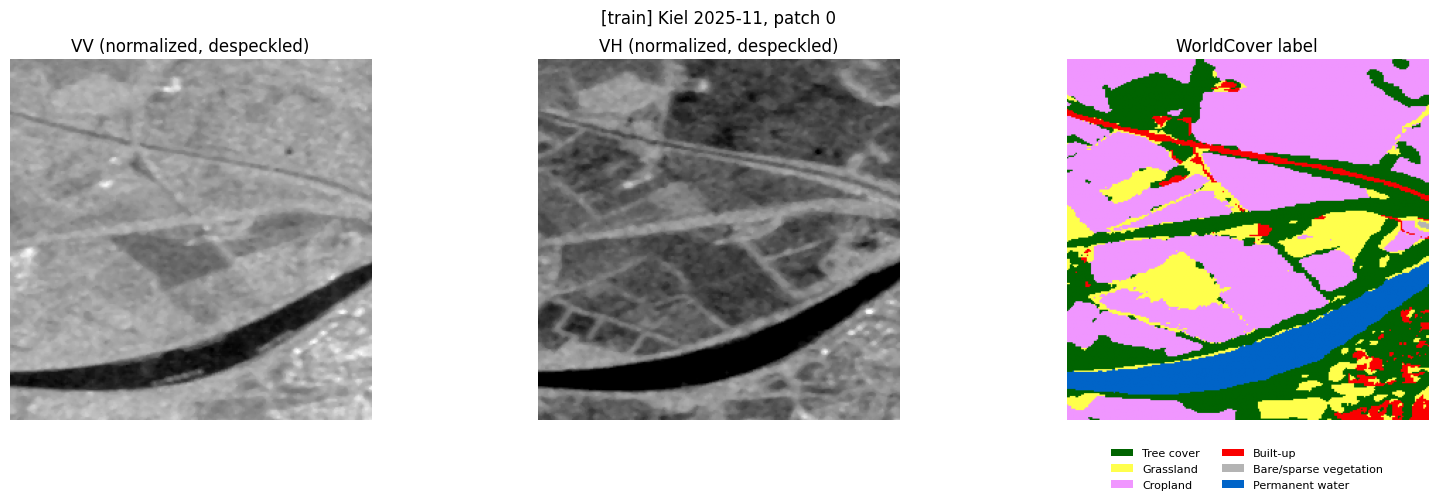

[val] Freiburg: image range 0.10 to 0.97, classes [10 30 40 50 60 80]


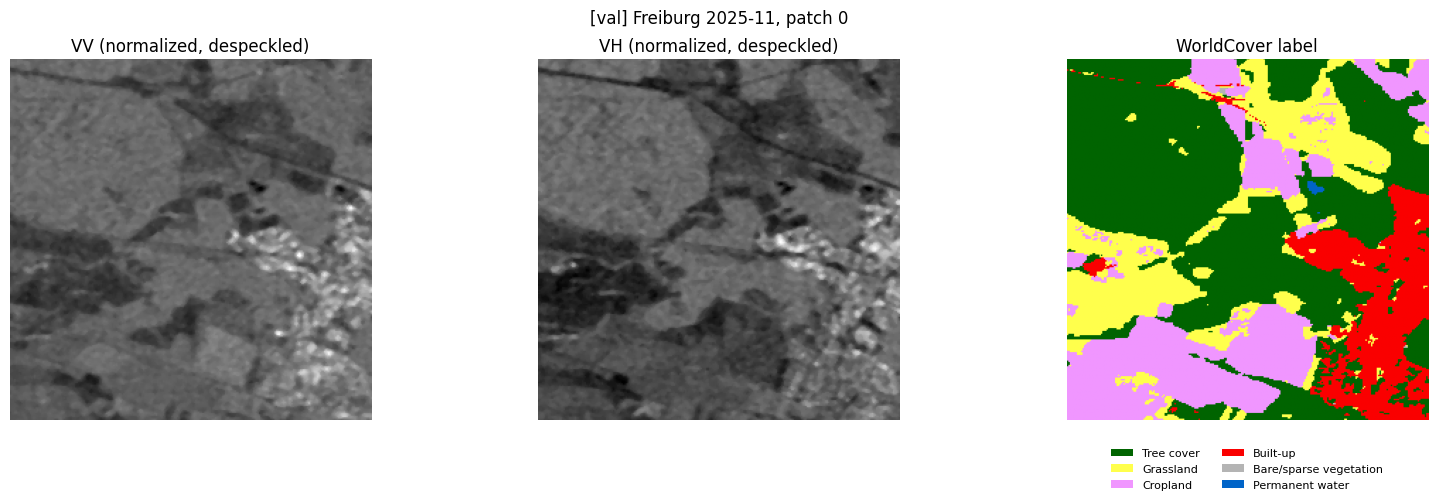

[test_same_region] Bremen: image range 0.00 to 1.00, classes [10 30 40 50 60 80]


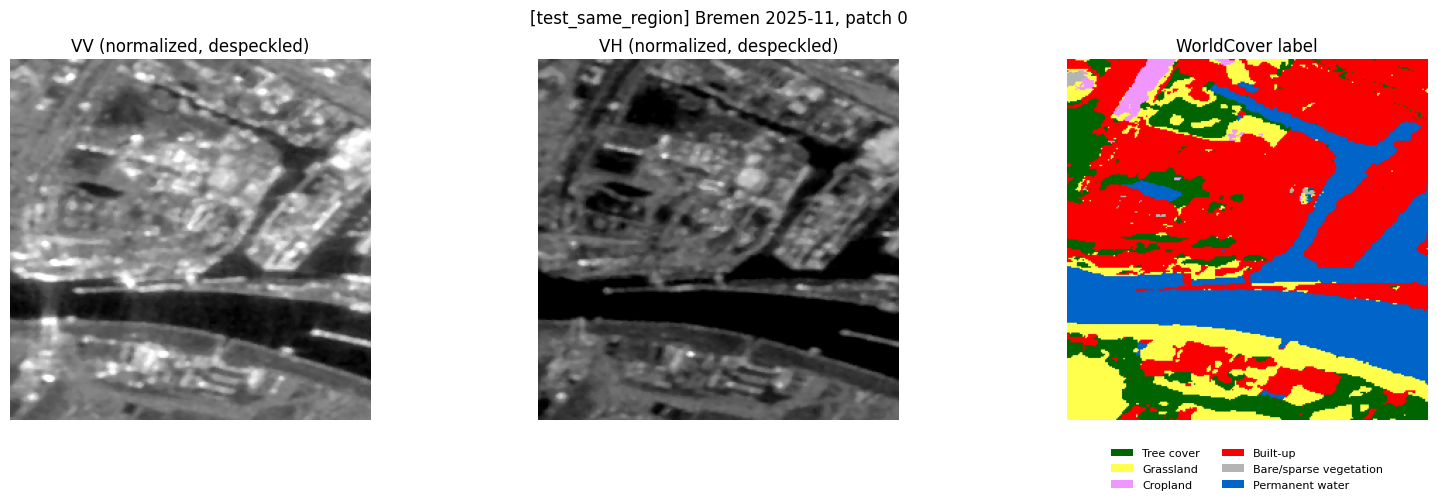

[test_similar_unseen] EastLondon: image range 0.00 to 0.87, classes [10 20 30 40 50 60 80]


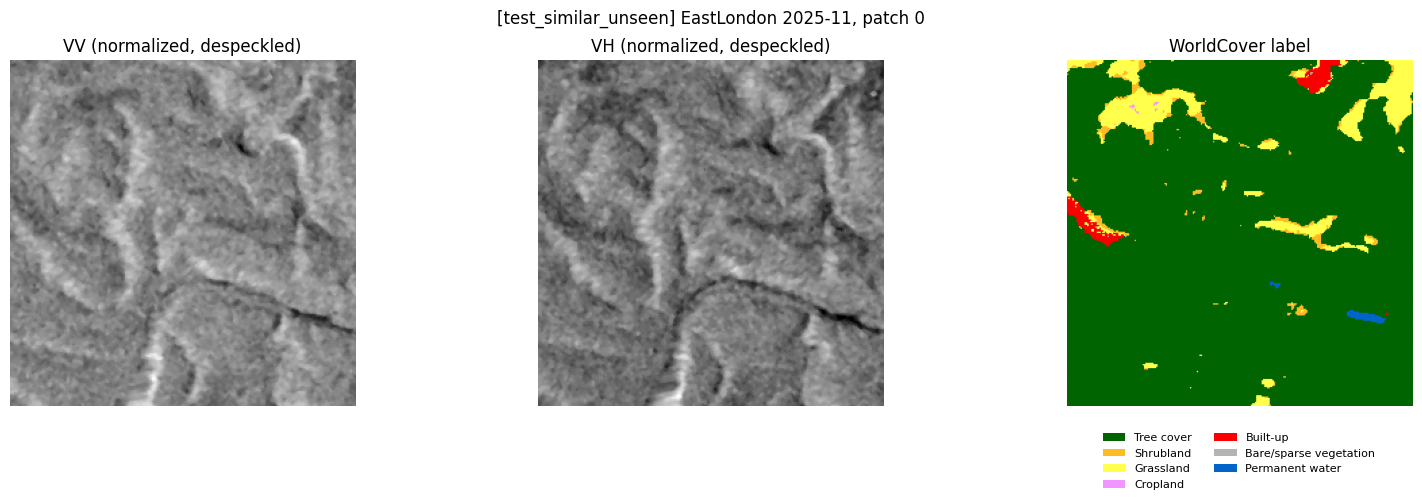

[test_dissimilar] Mumbai: image range 0.00 to 0.88, classes [10 30 40 50 60 80]


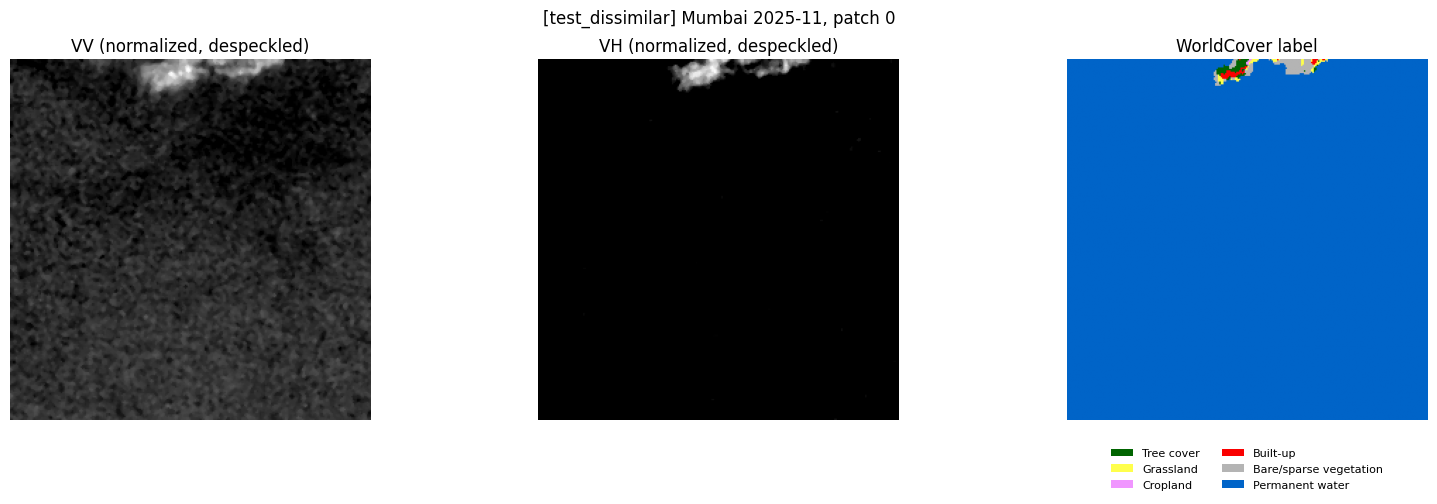

In [11]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Fixed class codes, names, and colors so the same class always maps to the same color
class_codes = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]
class_names = {
    10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
    50: "Built-up", 60: "Bare/sparse vegetation", 70: "Snow/ice",
    80: "Permanent water", 90: "Herbaceous wetland", 95: "Mangroves", 100: "Moss/lichen"
}
class_colors = [
    "#006400", "#ffbb22", "#ffff4c", "#f096ff",
    "#fa0000", "#b4b4b4", "#f0f0f0",
    "#0064c8", "#0096a0", "#00cf75", "#fae6a0"
]
cmap = ListedColormap(class_colors)
boundaries = [c - 5 for c in class_codes] + [class_codes[-1] + 5]
norm = BoundaryNorm(boundaries, cmap.N)

splits_to_check = ['train', 'val', 'test_same_region', 'test_similar_unseen', 'test_dissimilar']

for split_name in splits_to_check:
    split_rows = patch_df[patch_df['split'] == split_name]
    if len(split_rows) == 0:
        print(f"No patches found for split '{split_name}', skipping")
        continue

    sample_patch = split_rows.iloc[0]
    img = np.load(f"{PATCH_FOLDER}/{sample_patch['image_patch']}")
    lbl = np.load(f"{PATCH_FOLDER}/{sample_patch['label_patch']}")

    print(f"[{split_name}] {sample_patch['city']}: image range {img.min():.2f} to {img.max():.2f}, classes {np.unique(lbl)}")

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    axes[0].imshow(img[0], cmap='gray')
    axes[0].set_title('VV (normalized, despeckled)')
    axes[0].axis('off')

    axes[1].imshow(img[1], cmap='gray')
    axes[1].set_title('VH (normalized, despeckled)')
    axes[1].axis('off')

    axes[2].imshow(lbl, cmap=cmap, norm=norm)
    axes[2].set_title('WorldCover label')
    axes[2].axis('off')

    present_classes = sorted(np.unique(lbl))
    legend_handles = [
        Patch(facecolor=class_colors[class_codes.index(c)], label=class_names[c])
        for c in present_classes if c in class_codes
    ]
    axes[2].legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, -0.05),
                   ncol=2, fontsize=8, frameon=False)

    plt.suptitle(f"[{split_name}] {sample_patch['city']} {sample_patch['year']}-{sample_patch['month']:02d}, patch {sample_patch['patch_id']}")
    plt.tight_layout()
    plt.show()

## Cell 12: Class distribution across the full dataset
Counts pixel values per class across every processed patch in all 32 cities to quantify class balance. This distribution informs the loss function choice (e.g. weighting or Dice-based loss for imbalanced classes) and the decision on which near-absent classes to merge or ignore in the next model training step. A progress line prints periodically since this now scans patches from 32 cities.

Counting class pixels across 12288 patches...
  [0/12288] counted so far
  [200/12288] counted so far
  [400/12288] counted so far
  [600/12288] counted so far
  [800/12288] counted so far
  [1000/12288] counted so far
  [1200/12288] counted so far
  [1400/12288] counted so far
  [1600/12288] counted so far
  [1800/12288] counted so far
  [2000/12288] counted so far
  [2200/12288] counted so far
  [2400/12288] counted so far
  [2600/12288] counted so far
  [2800/12288] counted so far
  [3000/12288] counted so far
  [3200/12288] counted so far
  [3400/12288] counted so far
  [3600/12288] counted so far
  [3800/12288] counted so far
  [4000/12288] counted so far
  [4200/12288] counted so far
  [4400/12288] counted so far
  [4600/12288] counted so far
  [4800/12288] counted so far
  [5000/12288] counted so far
  [5200/12288] counted so far
  [5400/12288] counted so far
  [5600/12288] counted so far
  [5800/12288] counted so far
  [6000/12288] counted so far
  [6200/12288] counted so far
 

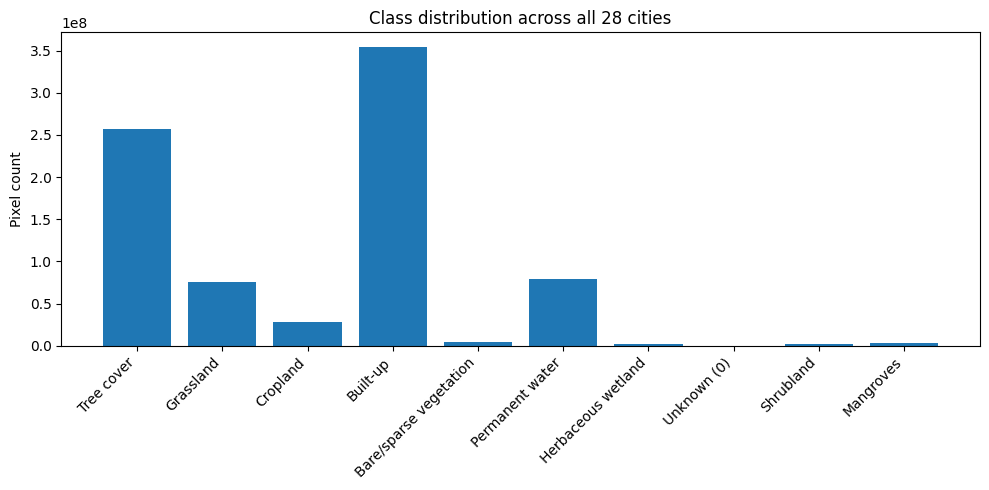

In [12]:
class_names = {
    10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
    50: "Built-up", 60: "Bare/sparse vegetation", 70: "Snow/ice",
    80: "Permanent water", 90: "Herbaceous wetland", 95: "Mangroves", 100: "Moss/lichen"
}

class_pixel_counts = {}
total_patches = len(patch_df)

print(f"Counting class pixels across {total_patches} patches...")

for i, row in patch_df.iterrows():
    if i % 200 == 0:
        print(f"  [{i}/{total_patches}] counted so far")
    lbl = np.load(f"{PATCH_FOLDER}/{row['label_patch']}")
    values, counts = np.unique(lbl, return_counts=True)
    for v, c in zip(values, counts):
        class_pixel_counts[int(v)] = class_pixel_counts.get(int(v), 0) + int(c)

print("Counting complete.")

labels = [class_names.get(k, f"Unknown ({k})") for k in class_pixel_counts.keys()]
values = list(class_pixel_counts.values())

plt.figure(figsize=(10, 5))
plt.bar(labels, values)
plt.ylabel("Pixel count")
plt.title("Class distribution across all 28 cities")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()